In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = {
    "Study_Hours": [
        2, 3, 4, 5, 6, 7, 8, 9,
        2, 4, 5, 6, 7, 8, 9, 10,
        3, 5, 6, 7, 8, 9
    ],

    "Attendance": [
        60, 65, 70, 75, 80, 85, 90, 95,
        62, 72, 77, 82, 87, 91, 94, 97,
        68, 76, 84, 88, 92, 96
    ],

    "Assignment_Score": [
        55, 60, 65, 68, 72, 78, 84, 90,
        58, 66, 71, 75, 80, 86, 91, 95,
        62, 70, 76, 82, 88, 93
    ],

    "Final_Marks": [
        50, 55, 62, 68, 73, 80, 86, 92,
        52, 63, 69, 74, 82, 88, 93, 97,
        58, 68, 75, 81, 89, 95
    ]
}

df = pd.DataFrame(data)

df.head()

,Study_Hours,Attendance,Assignment_Score,Final_Marks
0,2,60,55,50
1,3,65,60,55
2,4,70,65,62
3,5,75,68,68
4,6,80,72,73


In [3]:
df["Result"] = np.where(
    df["Final_Marks"] >= 60,
    1,
    0
)

print(df.head())

   Study_Hours  Attendance  Assignment_Score  Final_Marks  Result
0            2          60                55           50       0
1            3          65                60           55       0
2            4          70                65           62       1
3            5          75                68           68       1
4            6          80                72           73       1


In [4]:
X = df[
    ["Study_Hours", "Attendance", "Assignment_Score"]
]

y = df["Result"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Study_Hours  Attendance  Assignment_Score
0            2          60                55
1            3          65                60
2            4          70                65
3            5          75                68
4            6          80                72

Target:
0    0
1    0
2    1
3    1
4    1
Name: Result, dtype: int64


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 17
Testing samples: 5


In [6]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression())
])

print(pipeline)

Pipeline(steps=[('scaler', StandardScaler()), ('model', LogisticRegression())])


In [7]:
pipeline.fit(
    X_train,
    y_train
)

print("Pipeline trained successfully!")

Pipeline trained successfully!


In [8]:
predictions = pipeline.predict(X_test)

print("Predictions:")
print(predictions)

Predictions:
[0 1 1 1 1]


In [9]:
accuracy = accuracy_score(
    y_test,
    predictions
)

print("Pipeline Accuracy:", accuracy)

Pipeline Accuracy: 1.0


In [10]:
X_cluster = df[
    ["Study_Hours", "Attendance", "Assignment_Score"]
]

print(X_cluster.head())

   Study_Hours  Attendance  Assignment_Score
0            2          60                55
1            3          65                60
2            4          70                65
3            5          75                68
4            6          80                72


In [11]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    X_cluster
)

print(X_scaled[:5])

[[-1.73975521 -1.8893203  -1.76732683]
 [-1.30970336 -1.44334341 -1.340061  ]
 [-0.87965151 -0.99736651 -0.91279518]
 [-0.44959966 -0.55138962 -0.65643568]
 [-0.01954781 -0.10541272 -0.31462302]]


In [12]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(
    X_scaled
)

print("Cluster Labels:")
print(kmeans_labels)

Cluster Labels:
[0 0 0 1 1 1 2 2 0 0 1 1 1 2 2 2 0 1 1 1 2 2]


In [13]:
df["KMeans_Cluster"] = kmeans_labels

print(df[
    [
        "Study_Hours",
        "Attendance",
        "Assignment_Score",
        "KMeans_Cluster"
    ]
])

    Study_Hours  Attendance  Assignment_Score  KMeans_Cluster
0             2          60                55               0
1             3          65                60               0
2             4          70                65               0
3             5          75                68               1
4             6          80                72               1
5             7          85                78               1
6             8          90                84               2
7             9          95                90               2
8             2          62                58               0
9             4          72                66               0
10            5          77                71               1
11            6          82                75               1
12            7          87                80               1
13            8          91                86               2
14            9          94                91               2
15      

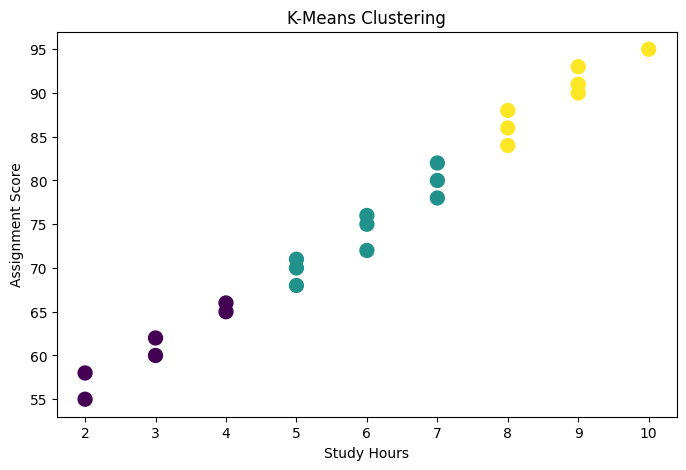

In [14]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Study_Hours"],
    df["Assignment_Score"],
    c=df["KMeans_Cluster"],
    s=100
)

plt.title("K-Means Clustering")
plt.xlabel("Study Hours")
plt.ylabel("Assignment Score")

plt.show()

In [15]:
kmeans_score = silhouette_score(
    X_scaled,
    kmeans_labels
)

print("K-Means Silhouette Score:", kmeans_score)

K-Means Silhouette Score: 0.5393681656554205


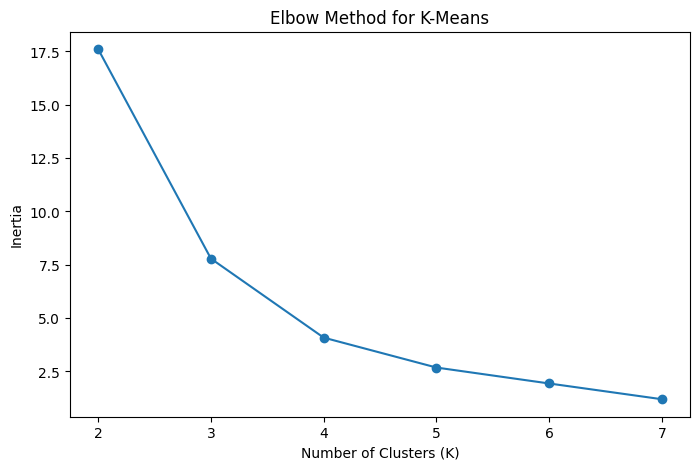

In [16]:
inertia = []

for k in range(2, 8):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 8),
    inertia,
    marker="o"
)

plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.show()

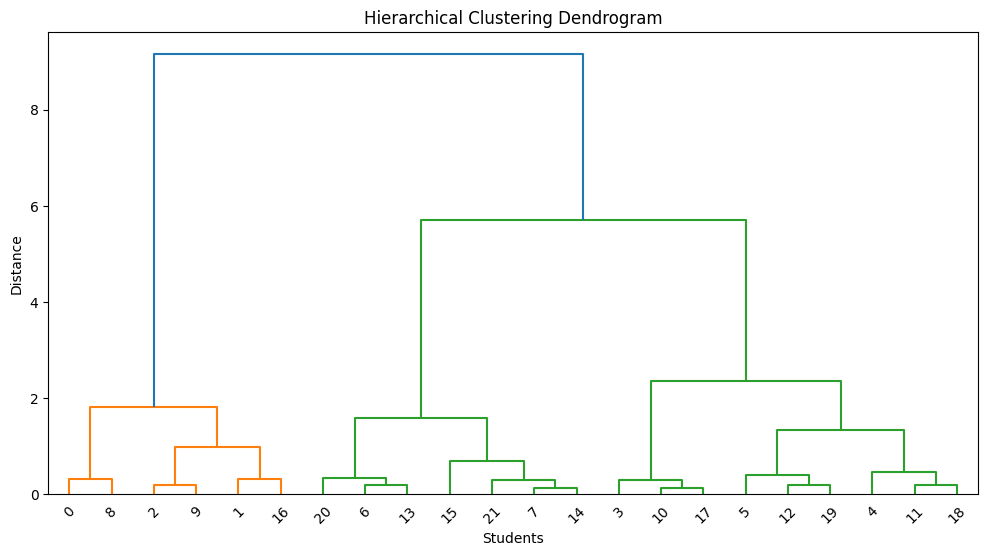

In [17]:
linked = linkage(
    X_scaled,
    method="ward"
)

plt.figure(figsize=(12, 6))

dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Students")
plt.ylabel("Distance")

plt.show()

In [18]:
hierarchical = AgglomerativeClustering(
    n_clusters=3
)

hierarchical_labels = hierarchical.fit_predict(
    X_scaled
)

print("Hierarchical Cluster Labels:")
print(hierarchical_labels)

Hierarchical Cluster Labels:
[1 1 1 0 0 0 2 2 1 1 0 0 0 2 2 2 1 0 0 0 2 2]


In [19]:
df["Hierarchical_Cluster"] = hierarchical_labels

print(
    df[
        [
            "Study_Hours",
            "Attendance",
            "Assignment_Score",
            "Hierarchical_Cluster"
        ]
    ]
)

    Study_Hours  Attendance  Assignment_Score  Hierarchical_Cluster
0             2          60                55                     1
1             3          65                60                     1
2             4          70                65                     1
3             5          75                68                     0
4             6          80                72                     0
5             7          85                78                     0
6             8          90                84                     2
7             9          95                90                     2
8             2          62                58                     1
9             4          72                66                     1
10            5          77                71                     0
11            6          82                75                     0
12            7          87                80                     0
13            8          91                86   

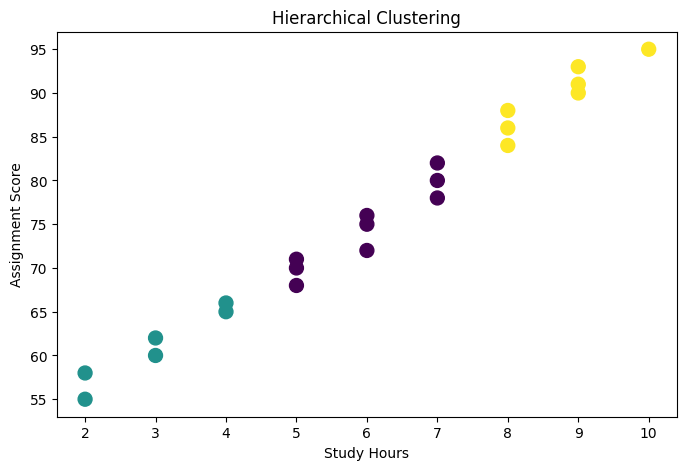

In [20]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Study_Hours"],
    df["Assignment_Score"],
    c=df["Hierarchical_Cluster"],
    s=100
)

plt.title("Hierarchical Clustering")
plt.xlabel("Study Hours")
plt.ylabel("Assignment Score")

plt.show()

In [21]:
hierarchical_score = silhouette_score(
    X_scaled,
    hierarchical_labels
)

print(
    "Hierarchical Clustering Silhouette Score:",
    hierarchical_score
)

Hierarchical Clustering Silhouette Score: 0.5393681656554205


In [22]:
dbscan = DBSCAN(
    eps=1.2,
    min_samples=2
)

dbscan_labels = dbscan.fit_predict(
    X_scaled
)

print("DBSCAN Labels:")
print(dbscan_labels)

DBSCAN Labels:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [23]:
df["DBSCAN_Cluster"] = dbscan_labels

print(
    df[
        [
            "Study_Hours",
            "Attendance",
            "Assignment_Score",
            "DBSCAN_Cluster"
        ]
    ]
)

    Study_Hours  Attendance  Assignment_Score  DBSCAN_Cluster
0             2          60                55               0
1             3          65                60               0
2             4          70                65               0
3             5          75                68               0
4             6          80                72               0
5             7          85                78               0
6             8          90                84               0
7             9          95                90               0
8             2          62                58               0
9             4          72                66               0
10            5          77                71               0
11            6          82                75               0
12            7          87                80               0
13            8          91                86               0
14            9          94                91               0
15      

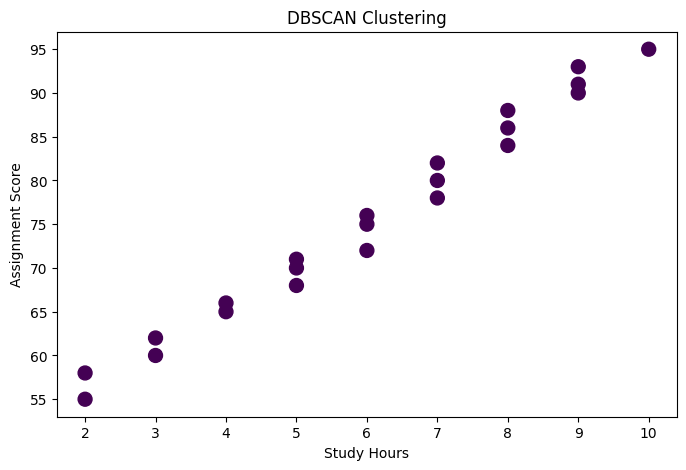

In [24]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Study_Hours"],
    df["Assignment_Score"],
    c=df["DBSCAN_Cluster"],
    s=100
)

plt.title("DBSCAN Clustering")
plt.xlabel("Study Hours")
plt.ylabel("Assignment Score")

plt.show()

In [25]:
print("==========================================")
print("       CLUSTERING COMPARISON")
print("==========================================")

print("\nK-Means Silhouette Score:")
print(kmeans_score)

print("\nHierarchical Silhouette Score:")
print(hierarchical_score)

print("\nDBSCAN Clusters:")
print(set(dbscan_labels))

       CLUSTERING COMPARISON

K-Means Silhouette Score:
0.5393681656554205

Hierarchical Silhouette Score:
0.5393681656554205

DBSCAN Clusters:
{np.int64(0)}


In [26]:
comparison = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "Hierarchical",
        "DBSCAN"
    ],

    "Number_of_Clusters": [
        len(set(kmeans_labels)),
        len(set(hierarchical_labels)),
        len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
    ],

    "Silhouette_Score": [
        kmeans_score,
        hierarchical_score,
        silhouette_score(
            X_scaled,
            dbscan_labels
        ) if len(set(dbscan_labels)) > 1 else np.nan
    ]
})

print(comparison)

      Algorithm  Number_of_Clusters  Silhouette_Score
0       K-Means                   3          0.539368
1  Hierarchical                   3          0.539368
2        DBSCAN                   1               NaN


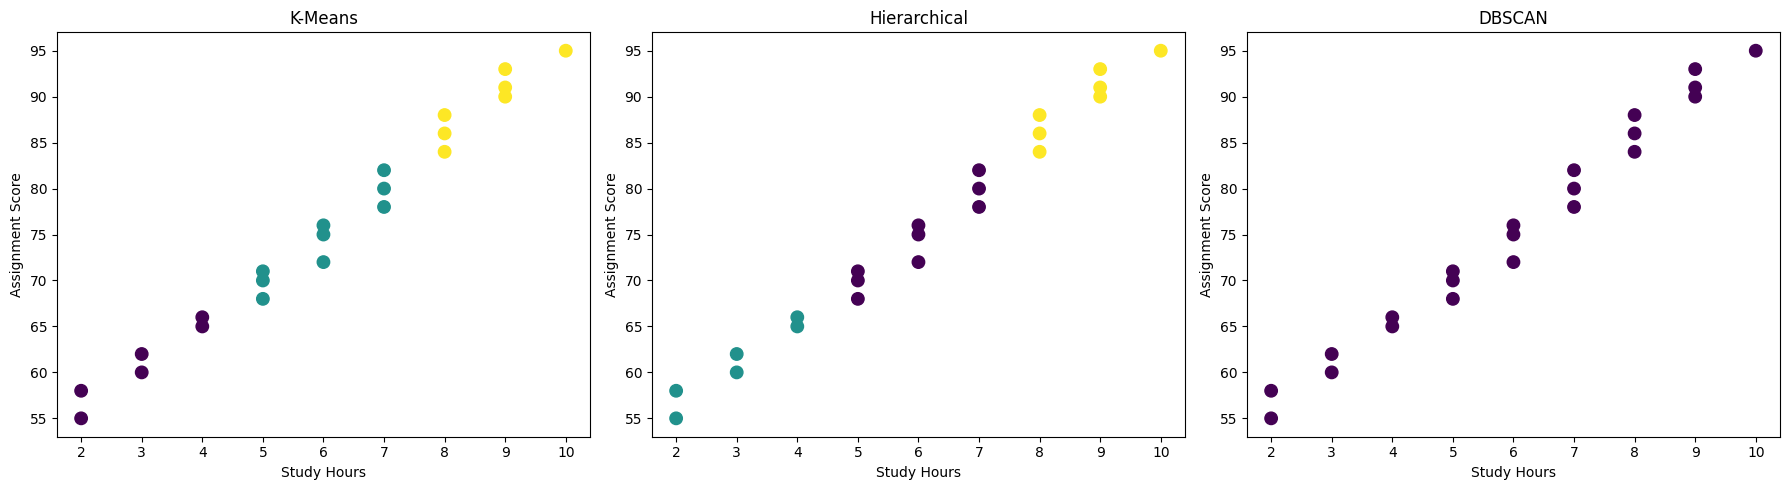

In [27]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

# K-Means
axes[0].scatter(
    df["Study_Hours"],
    df["Assignment_Score"],
    c=kmeans_labels,
    s=80
)

axes[0].set_title("K-Means")
axes[0].set_xlabel("Study Hours")
axes[0].set_ylabel("Assignment Score")


# Hierarchical
axes[1].scatter(
    df["Study_Hours"],
    df["Assignment_Score"],
    c=hierarchical_labels,
    s=80
)

axes[1].set_title("Hierarchical")
axes[1].set_xlabel("Study Hours")
axes[1].set_ylabel("Assignment Score")


# DBSCAN
axes[2].scatter(
    df["Study_Hours"],
    df["Assignment_Score"],
    c=dbscan_labels,
    s=80
)

axes[2].set_title("DBSCAN")
axes[2].set_xlabel("Study Hours")
axes[2].set_ylabel("Assignment Score")

plt.tight_layout()
plt.show()

In [28]:
print("==========================================")
print(" STUDENT PERFORMANCE CLUSTERING")
print("==========================================")

print("\nK-Means:")
print("Students are divided into 3 groups.")

print("\nHierarchical Clustering:")
print("Students are grouped using hierarchical relationships.")

print("\nDBSCAN:")
print("Students are grouped according to data density.")

print("\nScikit-learn Pipeline:")
print("Scaling + Logistic Regression were combined into one workflow.")

print("\nProject Completed Successfully!")

 STUDENT PERFORMANCE CLUSTERING

K-Means:
Students are divided into 3 groups.

Hierarchical Clustering:
Students are grouped using hierarchical relationships.

DBSCAN:
Students are grouped according to data density.

Scikit-learn Pipeline:
Scaling + Logistic Regression were combined into one workflow.

Project Completed Successfully!
